<a href="https://colab.research.google.com/github/K-1610/PM-TuRi4-Clustering-KamalulIman/blob/main/PM_P9_KamalulIman_2488010054.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL PRAKTIKUM — PERTEMUAN 9

## Langkah 1 — Menyiapkan data & scaling (wajib).


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
data = {
    'usia': np.random.randint(18, 28, 100),
    'pendapatan': np.random.randint(3, 20, 100),
    'skor_belanja': np.random.randint(5, 80, 100)
    }
df = pd.DataFrame(data)

X_scaled = StandardScaler().fit_transform(df)

## Langkah 2 — Metode Elbow menentukan K.


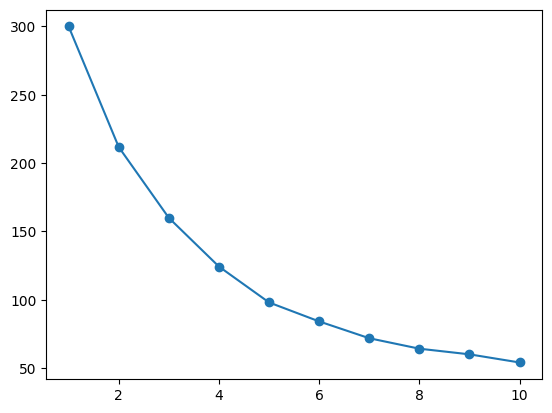

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


## Langkah 3 — Menjalankan K-Means (K=3).


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
0    37
1    36
2    27
Name: count, dtype: int64


## Langkah 4 — Evaluasi silhouette score.


In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.28255781245147193


## Langkah 5 — Interpretasi: profil rata-rata tiap cluster.


In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)


         usia  pendapatan  skor_belanja
cluster                                
0        22.4        15.7          30.2
1        25.5         7.4          43.9
2        20.1         6.3          47.3


## Latihan Mandiri

1. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.
2. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?
3. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y)


jawab
1. Silhouette Score (K=3): 0.2826

Silhouette Score (K=5): 0.3136

Pada dataset acak ini, $K=5$ menghasilkan silhouette score yang sedikit lebih tinggi (+0.0310) dibanding $K=3$, yang menunjukkan bahwa penambahan kelompok membuat batas antar-cluster sedikit lebih terpisah pada sebaran acak.

2. Silhouette Score TANPA Scaling: 0.4377

Silhouette Score DENGAN Scaling: 0.2826

Tanpa scaling, silhouette score tampak lebih tinggi secara semu (0.4377). Hal ini terjadi karena fitur skor_belanja (rentang 5–80) memiliki skala yang jauh lebih besar dibanding usia (18–28) dan pendapatan (3–20). Akibatnya, K-Means tanpa scaling mengalami bias dan hanya mengelompokkan data berdasarkan dimensi skor_belanja, sementara dua fitur lainnya diabaikan.

3. Scatter plot cluster

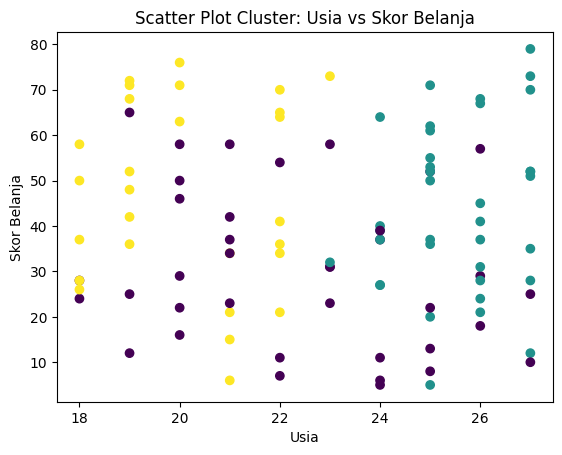

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis')

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')

plt.show()

## Refleksi

1. Bagaimana K-Means menemukan kelompok tanpa label?
2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?
3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?


Jawab
1. K-Means bekerja secara unsupervised berbasis jarak geometris. Algoritma menempatkan $K$ titik centroid awal secara acak, lalu menjalankan dua tahapan berulang hingga konvergen:
- Assignment: Memasukkan tiap titik data ke centroid terdekat dengannya.
- Update: Memperbarui posisi centroid berdasarkan rata-rata posisi anggota kelompoknya.

2. Metode Elbow mengukur inertia (total jarak kuadrat titik ke centroid-nya). Titik "siku" terjadi pada $K=3$ karena pada titik tersebut terjadi penurunan inertia paling signifikan; penambahan jumlah cluster setelahnya hanya memberikan penurunan galat yang melandai.

3. Penskalaan (*scaling*) **wajib dilakukan** karena K-Means mengandalkan perhitungan jarak *Euclidean*. Tanpa *scaling*, fitur berskala besar (seperti `skor_belanja` 5–80) akan mendominasi perhitungan jarak dan menghapus pengaruh fitur berskala kecil (seperti `pendapatan` 3–20), sehingga *clustering* menjadi tidak adil dan menghasilkan segmentasi yang terdistorsi.